In [1]:
import json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, confusion_matrix, roc_curve)
from xgboost import XGBClassifier

BASE_DIR = Path.cwd().parent
DATA_DIR, MODELS_DIR = BASE_DIR / "data", BASE_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
SEED = 42

In [2]:
X_tr = pd.read_csv(DATA_DIR / "X_train_final.csv")
X_te = pd.read_csv(DATA_DIR / "X_test_final.csv")
y_tr = pd.read_csv(DATA_DIR / "y_train_raw.csv").iloc[:, 0]
y_te = pd.read_csv(DATA_DIR / "y_test_raw.csv").iloc[:, 0]

assert list(X_tr.columns) == list(X_te.columns), "train/test columns differ"
assert len(X_tr) == len(y_tr) and len(X_te) == len(y_te), "X / y length mismatch"
assert X_tr.isna().sum().sum() == 0 and X_te.isna().sum().sum() == 0, "unexpected NaN"

print("train   :", X_tr.shape, "| positive rate", round(y_tr.mean(), 4))
print("hold-out:", X_te.shape, "| positive rate", round(y_te.mean(), 4))

train   : (83844, 19) | positive rate 0.0663
hold-out: (20961, 19) | positive rate 0.0663


In [3]:
COLS = list(X_tr.columns)
MONOTONE_UP = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalDelinquencies",
]
mono = tuple(1 if c in MONOTONE_UP else 0 for c in COLS)

PARAMS = dict(
    learning_rate=0.05, max_depth=3, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=5,
    monotone_constraints=mono,
    eval_metric="auc", n_jobs=-1, random_state=SEED,
)

X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=1)
es_model = XGBClassifier(n_estimators=2000, early_stopping_rounds=100, **PARAMS)
es_model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
N_TREES = int(es_model.best_iteration) + 1
print("trees chosen by early stopping:", N_TREES, "| val AUC:", round(es_model.best_score, 4))

trees chosen by early stopping: 259 | val AUC: 0.859


In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = np.zeros(len(X_tr))
fold_auc = []
for k, (i_fit, i_val) in enumerate(skf.split(X_tr, y_tr), 1):
    m = XGBClassifier(n_estimators=N_TREES, **PARAMS).fit(X_tr.iloc[i_fit], y_tr.iloc[i_fit])
    oof[i_val] = m.predict_proba(X_tr.iloc[i_val])[:, 1]
    fold_auc.append(roc_auc_score(y_tr.iloc[i_val], oof[i_val]))
    print(f"fold {k}: AUC = {fold_auc[-1]:.4f}")

print(f"\nCV AUC = {np.mean(fold_auc):.4f} +/- {np.std(fold_auc):.4f}")
print(f"OOF  AUC = {roc_auc_score(y_tr, oof):.4f} | PR-AUC = {average_precision_score(y_tr, oof):.4f}")

fold 1: AUC = 0.8623
fold 2: AUC = 0.8667
fold 3: AUC = 0.8586
fold 4: AUC = 0.8683
fold 5: AUC = 0.8648

CV AUC = 0.8641 +/- 0.0034
OOF  AUC = 0.8640 | PR-AUC = 0.3959


In [5]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof, y_tr)
oof_cal = iso.predict(oof)
print(f"Brier raw: {brier_score_loss(y_tr, oof):.4f} | calibrated: {brier_score_loss(y_tr, oof_cal):.4f}")
print(f"mean predicted: {oof_cal.mean():.4f} | actual rate: {y_tr.mean():.4f}")

Brier raw: 0.0489 | calibrated: 0.0487
mean predicted: 0.0663 | actual rate: 0.0663


In [6]:
COST_FN = 5.0   # approve a borrower who then defaults
COST_FP = 1.0   # flag / reject a borrower who would have paid

P, R, T = precision_recall_curve(y_tr, oof_cal)
f1 = 2 * P * R / (P + R + 1e-9)
thr_f1 = float(T[np.argmax(f1[:-1])])

grid = np.linspace(0.01, 0.9, 300)
costs = []
for t in grid:
    pred = oof_cal >= t
    costs.append(COST_FN * ((~pred) & (y_tr == 1)).sum() + COST_FP * (pred & (y_tr == 0)).sum())
thr_cost = float(grid[int(np.argmin(costs))])

print(f"F1-optimal threshold   : {thr_f1:.3f}")
print(f"cost-optimal threshold : {thr_cost:.3f}  (FN cost {COST_FN}, FP cost {COST_FP})")
THRESHOLD = thr_cost   # <- choose thr_f1 or thr_cost

F1-optimal threshold   : 0.231
cost-optimal threshold : 0.162  (FN cost 5.0, FP cost 1.0)


In [7]:
final = XGBClassifier(n_estimators=N_TREES, **PARAMS).fit(X_tr, y_tr)
p_raw = final.predict_proba(X_te)[:, 1]
p = iso.predict(p_raw)

print(f"ROC-AUC : {roc_auc_score(y_te, p_raw):.4f}")
print(f"PR-AUC  : {average_precision_score(y_te, p_raw):.4f}")
print(f"Brier   : raw {brier_score_loss(y_te, p_raw):.4f} -> calibrated {brier_score_loss(y_te, p):.4f}")
print(f"mean predicted {p.mean():.3f} vs actual {y_te.mean():.3f}")

def report(thr, name):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    print(f"\n[{name}] threshold = {thr:.3f}")
    print(f"  accuracy {(tp+tn)/len(y_te):.4f} | precision {tp/(tp+fp):.3f} | recall {tp/(tp+fn):.3f} | "
          f"F1 {2*tp/(2*tp+fp+fn):.3f} | NPV {tn/(tn+fn):.4f}")
    print(f"  TN={tn} FP={fp} FN={fn} TP={tp} | cost = {COST_FN*fn + COST_FP*fp:.0f}")

report(thr_f1, "F1-optimal")
report(thr_cost, "cost-optimal")
print(f"\nBaseline accuracy (predict nobody defaults): {1 - y_te.mean():.4f}")

ROC-AUC : 0.8662
PR-AUC  : 0.4029
Brier   : raw 0.0487 -> calibrated 0.0487
mean predicted 0.066 vs actual 0.066

[F1-optimal] threshold = 0.231
  accuracy 0.9219 | precision 0.419 | recall 0.462 | F1 0.440 | NPV 0.9615
  TN=18682 FP=889 FN=748 TP=642 | cost = 4629

[cost-optimal] threshold = 0.162
  accuracy 0.9028 | precision 0.351 | recall 0.549 | F1 0.428 | NPV 0.9666
  TN=18161 FP=1410 FN=627 TP=763 | cost = 4545

Baseline accuracy (predict nobody defaults): 0.9337


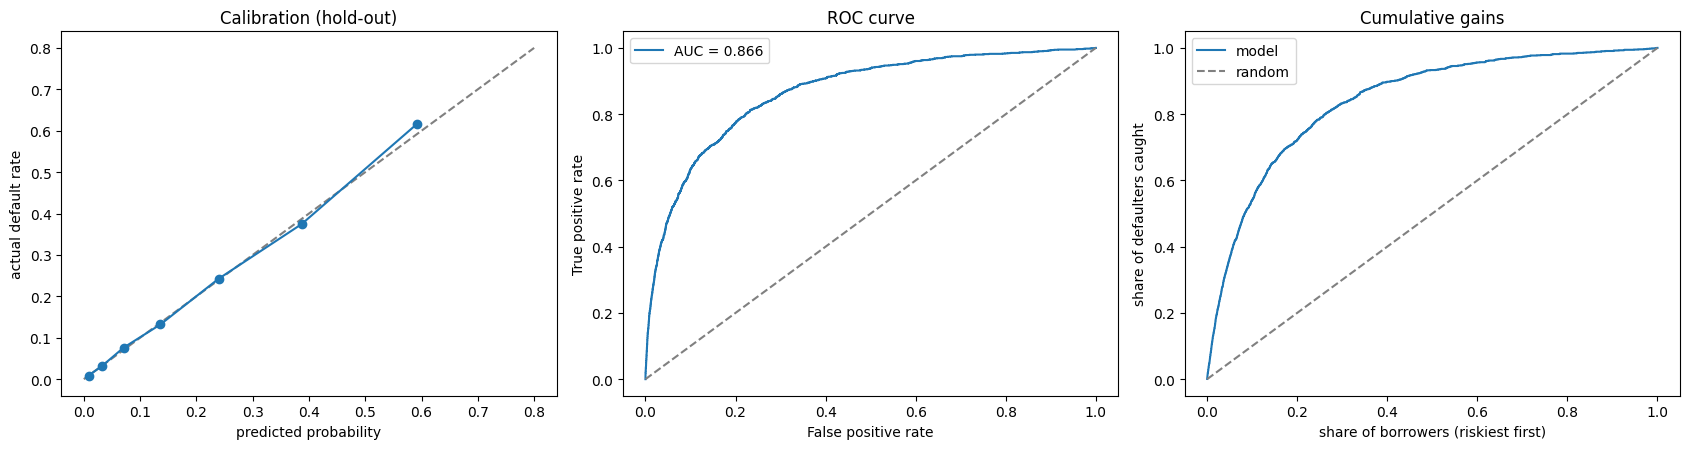

               pred  actual     n
bin                              
[0.0, 0.02)   0.008   0.009  9891
[0.02, 0.05)  0.033   0.032  5108
[0.05, 0.1)   0.071   0.076  2038
[0.1, 0.2)    0.136   0.132  2105
[0.2, 0.3)    0.239   0.242   623
[0.3, 0.5)    0.387   0.375   753
[0.5, 1.0)    0.592   0.616   443
top  5% riskiest -> catches 36.5% of defaulters
top 10% riskiest -> catches 54.0% of defaulters
top 20% riskiest -> catches 72.2% of defaulters


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

bins = [0, .02, .05, .1, .2, .3, .5, 1.0001]
d = pd.DataFrame({"p": p, "y": y_te.values})
d["bin"] = pd.cut(d.p, bins, right=False)
g = d.groupby("bin", observed=True).agg(pred=("p", "mean"), actual=("y", "mean"), n=("y", "size"))
ax[0].plot([0, .8], [0, .8], "--", c="gray"); ax[0].plot(g.pred, g.actual, "o-")
ax[0].set(title="Calibration (hold-out)", xlabel="predicted probability", ylabel="actual default rate")

fpr, tpr, _ = roc_curve(y_te, p_raw)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_te, p_raw):.3f}")
ax[1].plot([0, 1], [0, 1], "--", c="gray"); ax[1].legend()
ax[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")

order = np.argsort(-p)
gain = np.cumsum(y_te.values[order]) / y_te.sum()
x = np.arange(1, len(p) + 1) / len(p)
ax[2].plot(x, gain, label="model"); ax[2].plot([0, 1], [0, 1], "--", c="gray", label="random"); ax[2].legend()
ax[2].set(title="Cumulative gains", xlabel="share of borrowers (riskiest first)", ylabel="share of defaulters caught")
plt.tight_layout(); plt.show()

print(g.round(3))
for k in (0.05, 0.10, 0.20):
    n = int(len(p) * k)
    print(f"top {int(k*100):>2}% riskiest -> catches {y_te.values[order[:n]].sum() / y_te.sum():.1%} of defaulters")

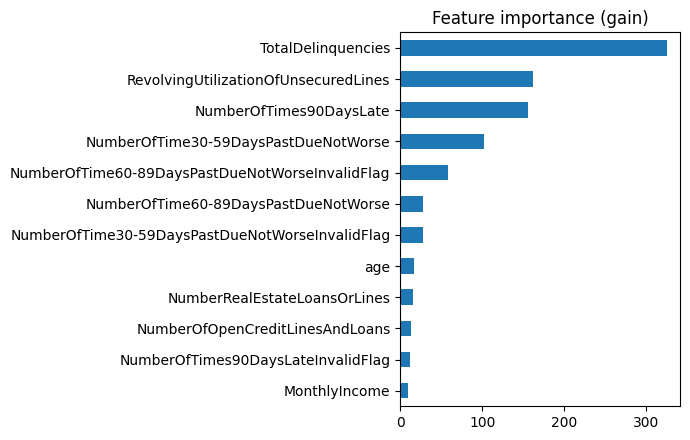

In [9]:
imp = pd.Series(final.get_booster().get_score(importance_type="gain")).sort_values()
imp.tail(12).plot.barh(figsize=(7, 4.5), title="Feature importance (gain)")
plt.tight_layout(); plt.show()

In [10]:
final.save_model(MODELS_DIR / "xgb.json")
joblib.dump(iso, MODELS_DIR / "calibrator.pkl")
with open(MODELS_DIR / "threshold.json", "w") as f:
    json.dump({
        "model": "XGBoost + isotonic calibration",
        "threshold": THRESHOLD,
        "threshold_f1": thr_f1,
        "threshold_cost": thr_cost,
        "cost_fn": COST_FN, "cost_fp": COST_FP,
        "n_trees": N_TREES,
        "feature_columns": COLS,
    }, f, indent=2)
print("saved: xgb.json, calibrator.pkl, threshold.json")

saved: xgb.json, calibrator.pkl, threshold.json
